# M4 Quarterly — N-BEATS vs CatBoost, MLP, TCN, Transformer, LSTM & GRU

**Can N-BEATS outperform simpler neural networks and CatBoost on heterogeneous quarterly series?**

This notebook uses the **official M4 Quarterly** dataset (24,000 series) from the [M4 forecasting competition](https://github.com/Mcompetitions/M4-methods). It compares all models on the **same series**, using **one 8-quarter holdout per series**, and reports macro-average **seasonal MASE** (quarterly seasonality `m=4`).

**What is M4 Quarterly?** M4 is a cross-industry forecasting benchmark with series from microeconomics, macroeconomics, finance, industry, demographics and others. These are not all tourism series. Each observation is one quarter (three months), and the official forecasting challenge is to predict **8 future quarters (two years)**. Some training series are as short as 16 quarters, so this implementation handles short histories with **left padding**.

**Models (same univariate lookback and forecast horizon):**
- Seasonal naive; simple MLP; GRU; LSTM; temporal convolution network (TCN); small patch Transformer.
- **Generic N-BEATS**, with residual backcast/forecast blocks.
- **Interpretable N-BEATS**, with explicit polynomial trend and quarterly Fourier seasonality bases.
- CatBoost (raw lags), CatBoost (engineered features).

**Important experiment boundaries:**
- Official competition `Quarterly-train.csv` is used for development; official `Quarterly-test.csv` is *never* used to fit or select models.
- Validation is the final 8 quarters of the official training file. Everything before that is the **model-fitting** period. For test inference, the full official training history (including validation observations) is available as past context, exactly as it would be in a real forecasting task.
- Early stopping uses **validation MASE**, not test performance; **no model is refit** on the validation block after selecting its best epoch. This is a comparison experiment, **not** a reproduction of the original competition submissions.
- Default `MAX_SERIES=2000` gives a deterministic representative sample of *series IDs* for practicality. Set `MAX_SERIES=None` to run all 24,000 (significantly more time/RAM). **A subset result is not a full-M4 result.**
- Any results come from executing this notebook; published paper scores are not prefilled.

**Data:** [official M4 methods repository](https://github.com/Mcompetitions/M4-methods/tree/master/Dataset) · [Monash M4 Quarterly archive](https://zenodo.org/records/4656410) · [N-BEATS original paper/code](https://github.com/ServiceNow/N-BEATS).

## 1. Environment and experiment settings

For Colab, select a GPU runtime if available. The **full 24,000-series run** may take hours; start with 200–500 series, then 2,000, and only then the full set. Dependencies are standard PyTorch and CatBoost; no external neural-forecast library is required.

In [1]:
# Uncomment in Colab / a fresh Python environment:
# %pip install -q "numpy>=1.24" "pandas>=2.0" "matplotlib>=3.7" "torch>=2.1" "catboost>=1.2" "tqdm>=4.64"
from pathlib import Path
from copy import deepcopy
import json, os, random, time, math, urllib.request, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import TensorDataset, DataLoader
from catboost import CatBoostRegressor
from IPython.display import display

SEED = 42
LOOKBACK = 24                  # 6 years; left-pad shorter histories
HORIZON = 8                    # official M4 Quarterly horizon
SEASONAL_PERIOD = 4           # quarterly seasonality
VAL_QUARTERS = 8              # held-out block at end of official train
MAX_SERIES = 2000             # None = all 24,000; 200 for a quick pilot
MAX_TRAIN_WINDOWS = 40000     # shared and deterministic for every model
MAX_EPOCHS = 40
PATIENCE = 7
BATCH_SIZE = 256
LEARNING_RATE = 1e-3
CATBOOST_ITERATIONS = 450
CATBOOST_PATIENCE = 55
CATBOOST_DEPTH = 6
RUN_ENGINEERED_CATBOOST = True

# Designed to fit typical Colab GPUs. Customize only using validation outcomes.
NBEATS_WIDTH = 128
NBEATS_HIDDEN_LAYERS = 3
NBEATS_GENERIC_BLOCKS = 4
NBEATS_INTERPRETABLE_BLOCKS_PER_STACK = 2
NEURAL_MODELS = ['MLP', 'GRU', 'LSTM', 'TCN', 'Patch Transformer',
                 'N-BEATS (generic)', 'N-BEATS (interpretable)']

DATA_DIR = Path('benchmark_data/m4_quarterly')
OUTPUT_DIR = Path('forecast_challenge_outputs/m4_quarterly')
DATA_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else
                      ('mps' if hasattr(torch.backends, 'mps') and torch.backends.mps.is_available() else 'cpu'))
torch.set_num_threads(min(4, os.cpu_count() or 1))
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
print('Device:', DEVICE, '| PyTorch:', torch.__version__, '| MAX_SERIES:', MAX_SERIES)

Device: mps | PyTorch: 2.12.0 | MAX_SERIES: 2000


## 2. Download and load the official M4 Quarterly train/test data

Each row in the official CSV is one series ID such as `Q1`, followed by quarterly observations. Train rows have different lengths and end in blank columns. The separate test file has exactly 8 future observations per series. We discard only **trailing** missing cells; internal missing observations trigger an error rather than silently changing the timeline.

In [2]:
BASE_URL = 'https://raw.githubusercontent.com/Mcompetitions/M4-methods/master/Dataset'
FILES = {
    'Quarterly-train.csv': f'{BASE_URL}/Train/Quarterly-train.csv',
    'Quarterly-test.csv': f'{BASE_URL}/Test/Quarterly-test.csv',
}

def ensure_download(filename, url):
    p = DATA_DIR / filename
    if not p.exists():
        print('Downloading', filename, '(may take a minute)')
        try:
            urllib.request.urlretrieve(url, p)
        except Exception as exc:
            raise RuntimeError(
                f'Could not download {filename}. Manually place the official CSV at {p} '
                f'from {url}'
            ) from exc
    if p.stat().st_size < 100:
        raise ValueError(f'Invalid or incomplete downloaded file: {p}')
    return p

paths = {name: ensure_download(name, url) for name, url in FILES.items()}
# Test CSV is read separately, so no test outcomes are ever in the training loader.
train_df = pd.read_csv(paths['Quarterly-train.csv'], low_memory=False)
test_df = pd.read_csv(paths['Quarterly-test.csv'], low_memory=False)
assert train_df.columns[0] == test_df.columns[0], 'Unexpected M4 CSV column format'
train_ids = train_df.iloc[:, 0].astype(str).to_numpy()
test_ids = test_df.iloc[:, 0].astype(str).to_numpy()
assert len(train_ids) == len(np.unique(train_ids))
assert len(test_ids) == len(np.unique(test_ids))
assert set(train_ids) == set(test_ids), 'Train/test IDs differ'
assert len(train_ids) == 24000, f'Expected 24,000 M4 quarterly series; got {len(train_ids)}'

train_values = train_df.iloc[:, 1:].to_numpy(dtype=np.float64)
test_values = test_df.iloc[:, 1:].to_numpy(dtype=np.float64)
assert test_values.shape == (24000, HORIZON), f'Unexpected test shape: {test_values.shape}'
assert np.isfinite(test_values).all()
test_lookup = dict(zip(test_ids, test_values))

# Fixed subset of IDs before creating any windows; not selected on test outcomes.
selection_rng = np.random.default_rng(SEED)
if MAX_SERIES is None:
    chosen_rows = np.arange(len(train_ids), dtype=int)
else:
    assert 1 <= MAX_SERIES <= len(train_ids)
    chosen_rows = np.sort(selection_rng.choice(len(train_ids), size=MAX_SERIES, replace=False))

series = []
for row_idx in chosen_rows:
    uid = str(train_ids[row_idx])
    row = train_values[row_idx]
    finite_idx = np.flatnonzero(np.isfinite(row))
    if len(finite_idx) == 0 or finite_idx[0] != 0:
        raise ValueError(f'Unexpected missing prefix for {uid}')
    observed = np.asarray(row[:finite_idx[-1] + 1], dtype=np.float64)
    if not np.isfinite(observed).all():
        raise ValueError(f'Internal missing value in {uid}: handle explicitly')
    if len(observed) < VAL_QUARTERS + SEASONAL_PERIOD + 1:
        raise ValueError(f'Insufficient history in {uid}')
    series.append({'id': uid, 'train_values': observed,
                   'test_values': np.asarray(test_lookup[uid], dtype=np.float64)})
assert len(series) == len(chosen_rows)
lengths = np.array([len(s['train_values']) for s in series])
print('Loaded:', len(series), 'series of the official 24,000',
      '| min/median/max train length:', lengths.min(), int(np.median(lengths)), lengths.max())
print('First ID:', series[0]['id'], '| train:', len(series[0]['train_values']),
      '| official test:', len(series[0]['test_values']))
# Release large wide CSV buffers before constructing the window arrays.
del train_df, test_df, train_values, test_values

Loaded: 2000 series of the official 24,000 | min/median/max train length: 17 88 738
First ID: Q28 | train: 59 | official test: 8


## 3. Evaluation protocol, normalization and short histories

**M4 split for each series:**

`[ model-fitting observations | validation: 8 quarters ] [ official test: 8 quarters ]`

All forecasts are *direct 8-quarter* forecasts, without recursive use of predictions. Every model receives exactly the most recent `LOOKBACK` observations. For a shorter history, the left-hand portion is filled with the **first observed value**, never with future values. All values are predicted as changes from the last observed value, normalized by the training-only mean absolute level; this makes global training more stable across series with vastly different units.

For **test MASE** the denominator is calculated on the *entire supplied official training series* (as in the M4 evaluation convention). For **validation MASE** it is calculated only on the history preceding validation. Training, validation and test never leak future targets into model features.

In [3]:
def seasonal_scale(y, m=SEASONAL_PERIOD):
    if len(y) <= m:
        return np.nan
    return float(np.mean(np.abs(y[m:] - y[:-m])))

def safe_normalizer(y):
    # Calculated exclusively from the pre-validation model-fitting segment.
    return max(float(np.mean(np.abs(y))), float(np.std(y)), 1e-5)

for s in series:
    tr = s['train_values']
    s['model_end'] = len(tr) - VAL_QUARTERS
    s['normalizer'] = safe_normalizer(tr[:s['model_end']])
    s['mase_val_denom'] = seasonal_scale(tr[:s['model_end']])
    s['mase_test_denom'] = seasonal_scale(tr)

# An origin t is always indexed in the OFFICIAL TRAINING array. Only Test gets t=len(train).
def window(s, t, part):
    train = s['train_values']
    hist = train[max(0, t - LOOKBACK):t]
    if len(hist) == 0:
        raise ValueError('Every window needs at least one actual past observation')
    if len(hist) < LOOKBACK:
        hist = np.pad(hist, (LOOKBACK - len(hist), 0), constant_values=float(hist[0]))
    anchor = float(train[t - 1])
    norm = s['normalizer']
    x = ((hist - anchor) / norm).astype(np.float32)
    if part == 'Test':
        truth = s['test_values']
    else:
        truth = train[t:t + HORIZON]
    assert len(truth) == HORIZON
    y = ((truth - anchor) / norm).astype(np.float32)
    return x, y, anchor

samples = {'Train': [], 'Validation': [], 'Test': []}
for sid, s in enumerate(series):
    end = s['model_end']
    # Need at least one observation prior to origin; short 16-quarter series may
    # provide no training windows, but STILL enter both evaluation sets.
    for t in range(SEASONAL_PERIOD + 1, end - HORIZON + 1):
        samples['Train'].append((sid, t))
    samples['Validation'].append((sid, end))
    samples['Test'].append((sid, len(s['train_values'])))

assert samples['Train'], 'No training windows in selected subset. Increase MAX_SERIES.'
if len(samples['Train']) > MAX_TRAIN_WINDOWS:
    idx = np.random.default_rng(SEED).choice(len(samples['Train']), size=MAX_TRAIN_WINDOWS, replace=False)
    samples['Train'] = [samples['Train'][int(j)] for j in sorted(idx)]
for sid, t in samples['Train']:
    assert t + HORIZON <= series[sid]['model_end']
for sid, t in samples['Validation']:
    assert t == series[sid]['model_end']
for sid, t in samples['Test']:
    assert t == len(series[sid]['train_values'])

def pack(part):
    xx, yy, anchors, sids = [], [], [], []
    for sid, t in samples[part]:
        x, y, anchor = window(series[sid], t, part)
        xx.append(x); yy.append(y); anchors.append(anchor); sids.append(sid)
    return {'x': np.stack(xx).astype(np.float32), 'y': np.stack(yy).astype(np.float32),
            'anchors': np.asarray(anchors, dtype=np.float64),
            'sids': np.asarray(sids, dtype=np.int32)}

packed = {part: pack(part) for part in samples}
for name, d in packed.items():
    print(f'{name:10s}: {len(d["y"]):7d} windows, x={d["x"].shape}, y={d["y"].shape}')
    assert np.all(np.isfinite(d['x'])) and np.all(np.isfinite(d['y']))
assert len(packed['Validation']['y']) == len(series)
assert len(packed['Test']['y']) == len(series)
print('Scales with defined validation MASE:', sum(np.isfinite(s['mase_val_denom']) and s['mase_val_denom']>0 for s in series))
print('Scales with defined test MASE:', sum(np.isfinite(s['mase_test_denom']) and s['mase_test_denom']>0 for s in series))

Train     :   40000 windows, x=(40000, 24), y=(40000, 8)
Validation:    2000 windows, x=(2000, 24), y=(2000, 8)
Test      :    2000 windows, x=(2000, 24), y=(2000, 8)
Scales with defined validation MASE: 2000
Scales with defined test MASE: 2000


## 4. Leakage audit and forecasting metrics

**MASE** is seasonal-Naive-scaled absolute error. Lower is better. For perfectly seasonal series with zero in-sample naive error, MASE is mathematically undefined; we report those as missing in MASE calculations rather than inventing a denominator. sMAPE and MAE are still reported for every series.

In [4]:
def restore(pred, part):
    """Normalized [N, 8] forecasts -> original measurement units."""
    d = packed[part]
    normalizers = np.asarray([series[int(sid)]['normalizer'] for sid in d['sids']])
    return np.asarray(pred, dtype=np.float64) * normalizers[:, None] + d['anchors'][:, None]

def actual(part):
    d = packed[part]
    normalizers = np.asarray([series[int(sid)]['normalizer'] for sid in d['sids']])
    return d['y'].astype(np.float64) * normalizers[:, None] + d['anchors'][:, None]

def per_series_metrics(pred, part):
    pp, yy = restore(pred, part), actual(part)
    errors = np.abs(yy - pp)
    mse_denom_key = 'mase_test_denom' if part == 'Test' else 'mase_val_denom'
    den = np.asarray([series[int(sid)][mse_denom_key] for sid in packed[part]['sids']])
    # Very small denominators relative to the scale mean the ratio is undefined / unstable.
    has_scale = np.isfinite(den) & (den > 1e-10)
    mase = np.full(len(den), np.nan)
    mase[has_scale] = errors.mean(axis=1)[has_scale] / den[has_scale]
    smape = 200 * (errors / np.maximum(np.abs(yy) + np.abs(pp), 1e-10)).mean(axis=1)
    return pd.DataFrame({'series_id': [series[int(sid)]['id'] for sid in packed[part]['sids']],
                         'mase': mase, 'smape': smape, 'mae': errors.mean(axis=1)})

def metrics(pred, part):
    v = per_series_metrics(pred, part)
    return {'mase': float(v['mase'].mean()), 'smape': float(v['smape'].mean()),
            'mae': float(v['mae'].mean()), 'valid_mase_series': int(v['mase'].notna().sum())}

# Leak test: replacing held-out targets must not change past features.
s = series[0]
t = s['model_end']
x_before = window(s, t, 'Validation')[0]
alt = dict(s)
alt['train_values'] = s['train_values'].copy()
alt['train_values'][t:] = 1e20
x_after = window(alt, t, 'Validation')[0]
assert np.array_equal(x_before, x_after)
assert all(np.isfinite(actual(part)).all() for part in ('Validation', 'Test'))
print('Leakage audit passed. Test targets are only used for final evaluation.')

Leakage audit passed. Test targets are only used for final evaluation.


## 5. Forecasting architectures (all univariate)

These networks take one tensor of `[batch, LOOKBACK]` and predict `[batch, 8]`. **No model receives future calendar features, identifiers or hidden test outcomes.** The patch model is deliberately a small transformer-style baseline; it is *not* a full production PatchTST reproduction.

N-BEATS: each block creates a **backcast** to remove part of the input residual and a **forecast** to add to the running future prediction. Generic N-BEATS learns the basis freely. Interpretable N-BEATS restricts the bases to polynomial trends and quarterly Fourier harmonics.

In [5]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(LOOKBACK, 256), nn.ReLU(), nn.Dropout(.1),
                                 nn.Linear(256, 128), nn.ReLU(), nn.Linear(128, HORIZON))
    def forward(self, x): return self.net(x)

class Recurrent(nn.Module):
    def __init__(self, kind):
        super().__init__()
        self.rnn = (nn.LSTM if kind == 'LSTM' else nn.GRU)(input_size=1, hidden_size=64, batch_first=True)
        self.head = nn.Linear(64, HORIZON)
    def forward(self, x):
        output, _ = self.rnn(x.unsqueeze(-1))
        return self.head(output[:, -1, :])

class TCN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv = nn.ModuleList([nn.Conv1d(1 if i == 0 else 64, 64, 3, dilation=2**i) for i in range(4)])
        self.head = nn.Linear(64, HORIZON)
    def forward(self, x):
        z = x.unsqueeze(1)
        for i, layer in enumerate(self.conv):
            dilation = 2**i
            z = F.relu(layer(F.pad(z, (2*dilation, 0))))
        return self.head(z[:, :, -1])

class PatchTransformer(nn.Module):
    def __init__(self, patch_len=4, stride=2):
        super().__init__()
        self.patch_len, self.stride = patch_len, stride
        self.n_patches = (LOOKBACK - patch_len)//stride + 1
        self.projection = nn.Linear(patch_len, 64)
        self.position = nn.Parameter(torch.zeros(1, self.n_patches, 64))
        encoder_layer = nn.TransformerEncoderLayer(64, 4, 128, dropout=.1, batch_first=True)
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=2, enable_nested_tensor=False)
        self.head = nn.Sequential(nn.Flatten(), nn.Linear(64*self.n_patches, 128),
                                  nn.ReLU(), nn.Linear(128, HORIZON))
    def forward(self, x):
        patches = x.unfold(-1, self.patch_len, self.stride)
        z = self.encoder(self.projection(patches) + self.position)
        return self.head(z)

class GenericNBEATSBlock(nn.Module):
    def __init__(self):
        super().__init__()
        layers, in_dim = [], LOOKBACK
        for _ in range(NBEATS_HIDDEN_LAYERS):
            layers += [nn.Linear(in_dim, NBEATS_WIDTH), nn.ReLU()]
            in_dim = NBEATS_WIDTH
        self.layers = nn.Sequential(*layers)
        self.backcast = nn.Linear(in_dim, LOOKBACK)
        self.forecast = nn.Linear(in_dim, HORIZON)
    def forward(self, x):
        z = self.layers(x)
        return self.backcast(z), self.forecast(z)

class GenericNBEATS(nn.Module):
    def __init__(self):
        super().__init__()
        self.blocks = nn.ModuleList([GenericNBEATSBlock() for _ in range(NBEATS_GENERIC_BLOCKS)])
    def forward(self, x):
        residual = x
        forecast = x.new_zeros((len(x), HORIZON))
        for block in self.blocks:
            backcast, forward = block(residual)
            residual = residual - backcast
            forecast = forecast + forward
        return forecast


def make_basis(kind):
    # Input chronology runs [-LOOKBACK+1, ..., 0]; forecast is [1, ..., HORIZON].
    past = np.arange(-LOOKBACK+1, 1, dtype=np.float64)
    fut = np.arange(1, HORIZON+1, dtype=np.float64)
    if kind == 'trend':
        def basis(t):
            t = t / LOOKBACK
            return np.stack([t**degree for degree in range(4)], axis=0)
    elif kind == 'seasonality':
        def basis(t):
            # Quarterly period 4: constant, cosine/sine fundamental and Nyquist harmonic.
            # k=2 sine would vanish on integer quarter indices, so it is omitted.
            return np.stack([np.ones_like(t), np.cos(2*np.pi*t/4),
                             np.sin(2*np.pi*t/4), np.cos(np.pi*t)], axis=0)
    else:
        raise ValueError(kind)
    return torch.tensor(basis(past), dtype=torch.float32), torch.tensor(basis(fut), dtype=torch.float32)

class BasisNBEATSBlock(nn.Module):
    """N-BEATS interpretable block with a predetermined trend or seasonal basis."""
    def __init__(self, kind):
        super().__init__()
        back_basis, fore_basis = make_basis(kind)
        self.register_buffer('back_basis', back_basis)
        self.register_buffer('fore_basis', fore_basis)
        layers, in_dim = [], LOOKBACK
        for _ in range(NBEATS_HIDDEN_LAYERS):
            layers += [nn.Linear(in_dim, NBEATS_WIDTH), nn.ReLU()]
            in_dim = NBEATS_WIDTH
        self.layers = nn.Sequential(*layers)
        self.theta_back = nn.Linear(in_dim, back_basis.shape[0])
        self.theta_fore = nn.Linear(in_dim, fore_basis.shape[0])
    def forward(self, x):
        z = self.layers(x)
        return self.theta_back(z) @ self.back_basis, self.theta_fore(z) @ self.fore_basis

class InterpretableNBEATS(nn.Module):
    def __init__(self):
        super().__init__()
        kinds = (['trend'] * NBEATS_INTERPRETABLE_BLOCKS_PER_STACK +
                 ['seasonality'] * NBEATS_INTERPRETABLE_BLOCKS_PER_STACK)
        self.blocks = nn.ModuleList([BasisNBEATSBlock(kind) for kind in kinds])
    def forward(self, x):
        residual = x
        forecast = x.new_zeros((len(x), HORIZON))
        for block in self.blocks:
            backcast, forward = block(residual)
            residual = residual - backcast
            forecast = forecast + forward
        return forecast

FACTORIES = {
    'MLP': MLP,
    'GRU': lambda: Recurrent('GRU'),
    'LSTM': lambda: Recurrent('LSTM'),
    'TCN': TCN,
    'Patch Transformer': PatchTransformer,
    'N-BEATS (generic)': GenericNBEATS,
    'N-BEATS (interpretable)': InterpretableNBEATS,
}
for name in NEURAL_MODELS:
    model = FACTORIES[name]()
    x = torch.randn(3, LOOKBACK)
    y = model(x)
    assert y.shape == (3, HORIZON) and torch.isfinite(y).all(), name
    y.square().mean().backward()
    assert all(torch.isfinite(p.grad).all() for p in model.parameters() if p.grad is not None), name
    print(f'{name:24s}  params={sum(p.numel() for p in model.parameters()):,}')
print('Forward + backward checks passed for all 7 neural architectures.')

MLP                       params=40,328
GRU                       params=13,384
LSTM                      params=17,672
TCN                       params=37,832
Patch Transformer         params=159,240
N-BEATS (generic)         params=161,408
N-BEATS (interpretable)   params=149,024
Forward + backward checks passed for all 7 neural architectures.


## 6. Training and early stopping

Every network uses exactly the **same** sampled training windows, the **same** validation set, the **same** optimizer and the **same** stopping criterion. The loss is Smooth L1 on normalized forecast deltas; best checkpoints are chosen using **validation MASE**. Training times include CPU/GPU computation, not dataset download. These settings aim for a comparison, not exhaustive per-model hyperparameter optimization.

In [6]:
def get_loader(part, shuffle=False):
    d = packed[part]
    data = TensorDataset(torch.from_numpy(d['x']), torch.from_numpy(d['y']))
    return DataLoader(data, batch_size=BATCH_SIZE, shuffle=shuffle, num_workers=0)

@torch.no_grad()
def predict_model(model, part):
    model.eval()
    pred = []
    for x, _ in get_loader(part):
        pred.append(model(x.to(DEVICE)).cpu().numpy())
    return np.concatenate(pred, axis=0)

def train_model(name):
    # Seed reset makes runs repeatable; it does not force identical architectures to share weights.
    torch.manual_seed(SEED)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
    model = FACTORIES[name]().to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
    best_score, best_epoch, best_state, stale = np.inf, None, None, 0
    history = []
    for epoch in range(1, MAX_EPOCHS+1):
        model.train()
        loss_total, seen = 0., 0
        for x, y in get_loader('Train', shuffle=True):
            x, y = x.to(DEVICE), y.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            yp = model(x)
            loss = F.smooth_l1_loss(yp, y)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            loss_total += float(loss.item()) * len(x)
            seen += len(x)
        val = predict_model(model, 'Validation')
        val_mase = metrics(val, 'Validation')['mase']
        if not np.isfinite(val_mase):
            raise ValueError('Validation MASE is undefined: check selected series and denominators')
        history.append({'model': name, 'epoch': epoch, 'train_loss': loss_total/seen, 'val_mase': val_mase})
        if val_mase < best_score-1e-6:
            best_score, best_epoch, stale = val_mase, epoch, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            stale += 1
            if stale >= PATIENCE:
                break
    model.load_state_dict(best_state)
    return model, best_epoch, history

## 7. Fit the neural models and seasonal-naive control

To keep the CPU runtime practical, reduce `MAX_SERIES` or `MAX_EPOCHS` in the first settings cell. **Do not** choose the final dataset or parameters based on which method wins the test set.

In [7]:
def seasonal_naive(part):
    # Predict each future quarter by repeating the corresponding quarter from the last year.
    output = []
    for sid, t in samples[part]:
        s = series[sid]
        old = s['train_values']
        seasonal = old[t-SEASONAL_PERIOD:t]
        anchor = float(old[t-1])
        future = np.tile(seasonal, int(np.ceil(HORIZON / SEASONAL_PERIOD)))[:HORIZON]
        output.append(((future-anchor)/s['normalizer']).astype(np.float32))
    return np.stack(output)

rows, predictions, validation_predictions, training_logs = [], {}, {}, []
for name in NEURAL_MODELS:
    tic = time.perf_counter()
    model, best_epoch, hist = train_model(name)
    test_pred = predict_model(model, 'Test')
    val_pred = predict_model(model, 'Validation')
    predictions[name] = test_pred
    validation_predictions[name] = val_pred
    training_logs.extend(hist)
    scores = metrics(test_pred, 'Test')
    rows.append({'model': name, 'family': 'Neural', 'best_epoch': best_epoch,
                 'train_seconds': round(time.perf_counter()-tic, 2),
                 'val_mase': metrics(val_pred,'Validation')['mase'], **scores})
    print(f'{name:24s} | test MASE {scores["mase"]:.4f} | val MASE {rows[-1]["val_mase"]:.4f} | epoch {best_epoch}', flush=True)
    del model
    if torch.cuda.is_available(): torch.cuda.empty_cache()

for pname in ('Validation', 'Test'):
    pred = seasonal_naive(pname)
    if pname == 'Test': predictions['Seasonal naive'] = pred
    else: validation_predictions['Seasonal naive'] = pred
naive_score = metrics(predictions['Seasonal naive'], 'Test')
rows.append({'model': 'Seasonal naive', 'family': 'Naive', 'best_epoch': None,
             'train_seconds': 0., 'val_mase': metrics(validation_predictions['Seasonal naive'],'Validation')['mase'],
             **naive_score})
print('Seasonal naive test MASE:', round(naive_score['mase'], 4))

MLP                      | test MASE 1.2099 | val MASE 1.2273 | epoch 4
GRU                      | test MASE 1.2356 | val MASE 1.2345 | epoch 29
LSTM                     | test MASE 1.2655 | val MASE 1.2522 | epoch 24
TCN                      | test MASE 1.2210 | val MASE 1.2238 | epoch 5
Patch Transformer        | test MASE 1.2195 | val MASE 1.2267 | epoch 7
N-BEATS (generic)        | test MASE 1.2285 | val MASE 1.2404 | epoch 4
N-BEATS (interpretable)  | test MASE 1.2214 | val MASE 1.2323 | epoch 12
Seasonal naive test MASE: 1.6032


## 8. CatBoost: direct multi-output regression

CatBoost uses MultiRMSE to forecast all 8 steps simultaneously (not a recursive single-step regressor). Both variants use the **same 24 observed lag values** as all neural models. The engineered variant adds past-only rolling statistics and changes; it does not receive future covariates. Both use early stopping based on the separate validation slice.

In [8]:
def cat_features(part, engineered=False):
    x = packed[part]['x'].astype(np.float32)
    if not engineered:
        return x
    extra = np.column_stack([
        x.mean(1), x.std(1), x.min(1), x.max(1),
        x[:,-4:].mean(1), x[:,-8:].mean(1),
        x[:,-12:].mean(1), x[:,-16:].mean(1),
        x[:,-1]-x[:,-5], x[:,-1]-x[:,-9],
        x[:,-4:].std(1), x[:,-8:].std(1),
        x[:,-1]-x[:,0]
    ]).astype(np.float32)
    return np.concatenate([x, extra], axis=1)

for engineered in ([False, True] if RUN_ENGINEERED_CATBOOST else [False]):
    name = 'CatBoost (engineered)' if engineered else 'CatBoost (raw lags)'
    tic = time.perf_counter()
    cb = CatBoostRegressor(iterations=CATBOOST_ITERATIONS, depth=CATBOOST_DEPTH,
                           learning_rate=.05, loss_function='MultiRMSE', l2_leaf_reg=3,
                           random_seed=SEED, thread_count=min(4,os.cpu_count() or 1),
                           task_type='CPU', allow_writing_files=False)
    cb.fit(cat_features('Train', engineered), packed['Train']['y'],
           eval_set=(cat_features('Validation', engineered), packed['Validation']['y']),
           early_stopping_rounds=CATBOOST_PATIENCE, use_best_model=True, verbose=False)
    test_pred = np.asarray(cb.predict(cat_features('Test', engineered)), dtype=np.float32)
    val_pred = np.asarray(cb.predict(cat_features('Validation', engineered)), dtype=np.float32)
    predictions[name], validation_predictions[name] = test_pred, val_pred
    score = metrics(test_pred, 'Test')
    rows.append({'model': name, 'family': 'Tree', 'best_epoch': cb.tree_count_,
                 'train_seconds': round(time.perf_counter()-tic, 2),
                 'val_mase': metrics(val_pred,'Validation')['mase'], **score})
    print(f'{name:24s} | test MASE {score["mase"]:.4f} | val MASE {rows[-1]["val_mase"]:.4f} | trees {cb.tree_count_}', flush=True)

CatBoost (raw lags)      | test MASE 1.2523 | val MASE 1.2685 | trees 256
CatBoost (engineered)    | test MASE 1.3425 | val MASE 1.3439 | trees 37


## 9. Results: compare MASE, sMAPE and training time

The main metric is **macro MASE**: each included series has equal weight, regardless of scale. Test MASE ranks are descriptive only. Choose model/hyperparameter changes on **validation**, then treat test as a final untouched evaluation. The benchmark is explicitly labeled as a **2,000-series subset** unless you set `MAX_SERIES=None`.

M4 Quarterly | official 8-quarter holdout | subset size: 2000


,model,family,best_epoch,train_seconds,val_mase,mase,smape,mae,valid_mase_series
0,MLP,Neural,4.0,7.18,1.2273,1.2099,10.1241,579.5551,2000
1,Patch Transformer,Neural,7.0,24.91,1.2267,1.2195,10.2768,583.6919,2000
2,TCN,Neural,5.0,9.89,1.2238,1.2210,10.1690,583.3388,2000
3,N-BEATS (interpretable),Neural,12.0,28.04,1.2323,1.2214,10.4517,594.2548,2000
4,N-BEATS (generic),Neural,4.0,15.39,1.2404,1.2285,10.4170,588.1365,2000
5,GRU,Neural,29.0,60.40,1.2345,1.2356,10.4057,594.4645,2000
6,CatBoost (raw lags),Tree,256.0,3.40,1.2685,1.2523,10.3878,587.6526,2000
7,LSTM,Neural,24.0,27.22,1.2522,1.2655,10.5162,601.8771,2000
8,CatBoost (engineered),Tree,37.0,1.77,1.3439,1.3425,10.7666,611.9942,2000
9,Seasonal naive,Naive,NaN,0.00,1.5575,1.6032,12.4918,720.0344,2000


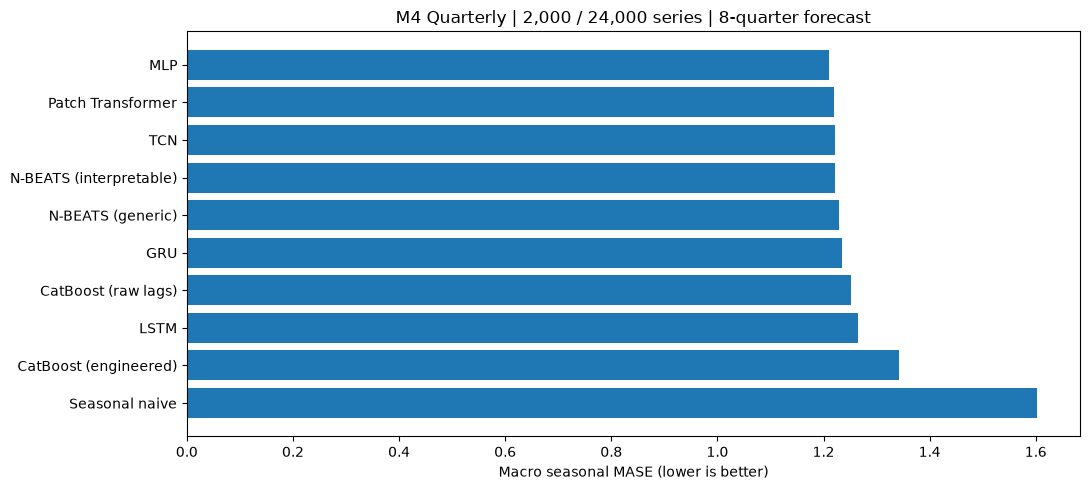

Validation-selected model: TCN | test MASE: 1.221


In [9]:
summary = pd.DataFrame(rows).sort_values('mase').reset_index(drop=True)
print('M4 Quarterly | official 8-quarter holdout | subset size:', len(series))
display(summary[['model','family','best_epoch','train_seconds','val_mase',
                 'mase','smape','mae','valid_mase_series']].round(4))
summary.to_csv(OUTPUT_DIR/'comparison.csv', index=False)
fig, ax = plt.subplots(figsize=(11,5))
order = summary.iloc[::-1]
ax.barh(order['model'], order['mase'])
ax.set(xlabel='Macro seasonal MASE (lower is better)',
       title=f'M4 Quarterly | {len(series):,} / 24,000 series | 8-quarter forecast')
fig.tight_layout()
fig.savefig(OUTPUT_DIR/'mase_ranking.png', dpi=150)
plt.show()
validation_best = summary.sort_values('val_mase').iloc[0]
print('Validation-selected model:', validation_best['model'], '| test MASE:',round(validation_best['mase'],4))

## 10. N-BEATS head-to-head: does it beat the MLP and CatBoost?

The per-series win rate shows whether N-BEATS beats another model on most series or simply wins on a few large outliers. Differences in **per-series MASE** are computed on exactly the same IDs.

In [10]:
per_model_series = []
for name, pred in predictions.items():
    v = per_series_metrics(pred, 'Test')
    v.insert(0, 'model', name)
    per_model_series.append(v)
per_series = pd.concat(per_model_series, ignore_index=True)
per_series.to_csv(OUTPUT_DIR/'per_series_metrics.csv', index=False)
wide = per_series.pivot(index='series_id',columns='model',values='mase')
compare_rows=[]
for nbeats_name in ('N-BEATS (generic)','N-BEATS (interpretable)'):
    for competitor in ('MLP','TCN','Patch Transformer','CatBoost (raw lags)','CatBoost (engineered)','Seasonal naive'):
        if competitor not in wide:
            continue
        pair = wide[[nbeats_name, competitor]].dropna()
        compare_rows.append({'NBEATS_model': nbeats_name, 'competitor': competitor,
                             'NBEATS_lower_MASE_pct': 100*float((pair[nbeats_name]<pair[competitor]).mean()),
                             'mean_MASE_difference_NBEATS_minus_other': float((pair[nbeats_name]-pair[competitor]).mean()),
                             'series_compared': len(pair)})
head_to_head = pd.DataFrame(compare_rows)
display(head_to_head.round(3))
head_to_head.to_csv(OUTPUT_DIR/'nbeats_head_to_head.csv', index=False)

,NBEATS_model,competitor,NBEATS_lower_MASE_pct,mean_MASE_difference_NBEATS_minus_other,series_compared
0,N-BEATS (generic),MLP,47.05,0.019,2000
1,N-BEATS (generic),TCN,49.40,0.007,2000
2,N-BEATS (generic),Patch Transformer,47.85,0.009,2000
3,N-BEATS (generic),CatBoost (raw lags),49.90,-0.024,2000
4,N-BEATS (generic),CatBoost (engineered),55.55,-0.114,2000
5,N-BEATS (generic),Seasonal naive,67.95,-0.375,2000
6,N-BEATS (interpretable),MLP,49.95,0.011,2000
7,N-BEATS (interpretable),TCN,53.75,0.000,2000
8,N-BEATS (interpretable),Patch Transformer,49.10,0.002,2000
9,N-BEATS (interpretable),CatBoost (raw lags),52.95,-0.031,2000


## 11. Errors by forecast horizon

This is useful for detecting architectures that do well at quarter 1–2 but extrapolate poorly at quarter 7–8.

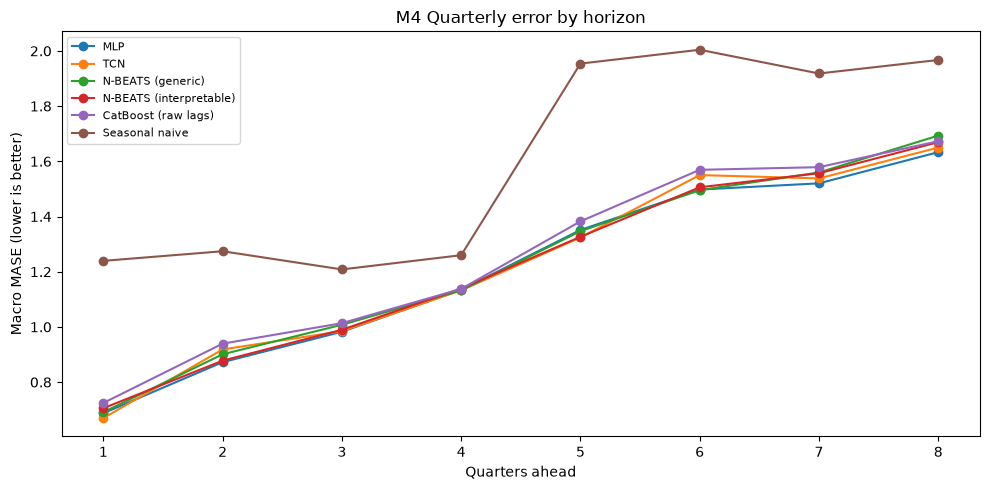

In [11]:
truth = actual('Test')
horizon_rows=[]
for name, pred in predictions.items():
    p = restore(pred, 'Test')
    den = np.asarray([s['mase_test_denom'] for s in series], dtype=float)
    valid = np.isfinite(den)&(den>1e-10)
    for h in range(HORIZON):
        err = np.abs(p[:,h]-truth[:,h])
        horizon_rows.append({'model':name, 'quarter_ahead':h+1,
                             'mase':float(np.mean(err[valid]/den[valid])),
                             'mae':float(err.mean())})
per_horizon=pd.DataFrame(horizon_rows)
per_horizon.to_csv(OUTPUT_DIR/'horizon_metrics.csv',index=False)
fig,ax=plt.subplots(figsize=(10,5))
for name in ['MLP','TCN','N-BEATS (generic)','N-BEATS (interpretable)',
             'CatBoost (raw lags)','Seasonal naive']:
    d=per_horizon[per_horizon.model==name]
    if not d.empty:ax.plot(d.quarter_ahead,d.mase,marker='o',label=name)
ax.set(xlabel='Quarters ahead',ylabel='Macro MASE (lower is better)',title='M4 Quarterly error by horizon')
ax.legend(fontsize=8)
fig.tight_layout();fig.savefig(OUTPUT_DIR/'mase_by_horizon.png',dpi=150);plt.show()

## 12. Illustrative forecast (not picked by test model performance)

Select the **median-length series** deterministically. Unlike picking the largest N-BEATS win, this doesn't cherry-pick an impressive example.

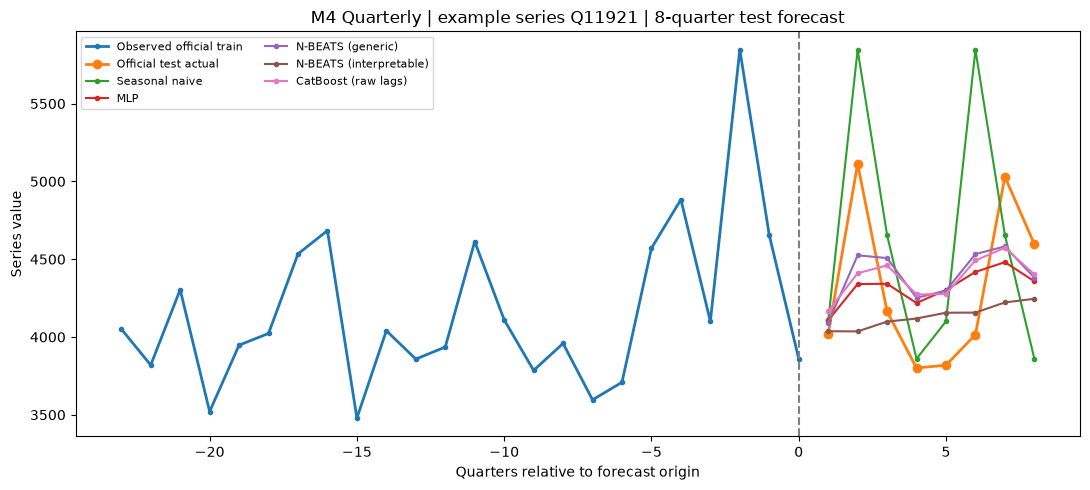

In [12]:
idx = int(np.argsort(lengths, kind='stable')[len(series)//2])
s = series[idx]
truth_series = s['test_values']
fig, ax = plt.subplots(figsize=(11,5))
recent=s['train_values'][-min(len(s['train_values']), 24):]
ax.plot(np.arange(-len(recent)+1,1),recent,marker='.',label='Observed official train',linewidth=2)
future=np.arange(1,HORIZON+1)
ax.plot(future,truth_series,marker='o',linewidth=2,label='Official test actual')
for name in ['Seasonal naive','MLP','N-BEATS (generic)','N-BEATS (interpretable)','CatBoost (raw lags)']:
    if name in predictions:
        curve=restore(predictions[name],'Test')[idx]
        ax.plot(future,curve,marker='.',label=name)
ax.axvline(0,color='gray',linestyle='--')
ax.set(title=f'M4 Quarterly | example series {s["id"]} | 8-quarter test forecast',
       xlabel='Quarters relative to forecast origin',ylabel='Series value')
ax.legend(fontsize=8,ncol=2)
fig.tight_layout();fig.savefig(OUTPUT_DIR/'example_forecast.png',dpi=150);plt.show()

## 13. Export all predictions, metrics, hyperparameters and model selection

The exported CSVs are intended for your GitHub repository and article. All numbers are generated by executing this notebook. No synthetic or published benchmark scores are inserted into results.

In [13]:
forecast_rows=[]
for name,pred in predictions.items():
    yhat=restore(pred,'Test')
    ytrue=actual('Test')
    for i,s in enumerate(series):
        for h in range(HORIZON):
            forecast_rows.append((name,s['id'],h+1,float(ytrue[i,h]),float(yhat[i,h])))
forecast_df=pd.DataFrame(forecast_rows,columns=['model','series_id','quarter_ahead','actual','prediction'])
forecast_df.to_csv(OUTPUT_DIR/'test_predictions.csv',index=False)
pd.DataFrame(training_logs).to_csv(OUTPUT_DIR/'neural_training_log.csv',index=False)
np.savez_compressed(OUTPUT_DIR/'normalized_test_predictions.npz',
                    **{name.lower().replace(' ','_').replace('-','').replace('(','').replace(')',''):pred
                       for name,pred in predictions.items()})
run_config={
    'dataset':'M4 Quarterly (official M4-methods Train and Test CSVs)',
    'source_urls': FILES, 'seed':SEED, 'sampled_series': len(series), 'total_official_series':24000,
    'series_sampling':'all' if MAX_SERIES is None else 'uniform random ID sample, seed 42',
    'lookback':LOOKBACK,'seasonal_period':SEASONAL_PERIOD,'horizon':HORIZON,
    'validation_quarters':VAL_QUARTERS,'train_windows':len(samples['Train']),
    'max_epochs':MAX_EPOCHS,'patience':PATIENCE,'batch_size':BATCH_SIZE,
    'neural_architectures':NEURAL_MODELS,'nbeats_width':NBEATS_WIDTH,
    'nbeats_generic_blocks':NBEATS_GENERIC_BLOCKS,
    'nbeats_interpretable_blocks_per_stack':NBEATS_INTERPRETABLE_BLOCKS_PER_STACK,
    'catboost_iterations':CATBOOST_ITERATIONS,'catboost_patience':CATBOOST_PATIENCE,
    'device':str(DEVICE),'python':platform.python_version(),
    'torch':torch.__version__,'catboost':__import__('catboost').__version__,
    'validation_selected_model':str(validation_best['model']),
    'note':'A controlled global-model comparison; not the official M4 submission/training protocol.'}
(OUTPUT_DIR/'run_info.json').write_text(json.dumps(run_config,indent=2),encoding='utf8')
print('Saved to:',OUTPUT_DIR.resolve())
print('Files:')
for p in sorted(OUTPUT_DIR.iterdir()): print(' ',p.name, f'{p.stat().st_size/1024:.1f} KB')

Saved to: /Users/adidror/code/time-series-forecasting/Time_Series_Benchmark_Final/forecast_challenge_outputs/m4_quarterly
Files:
  comparison.csv 1.1 KB
  example_forecast.png 131.1 KB
  horizon_metrics.csv 4.1 KB
  mase_by_horizon.png 102.1 KB
  mase_ranking.png 48.3 KB
  nbeats_head_to_head.csv 0.9 KB
  neural_training_log.csv 6.8 KB
  normalized_test_predictions.npz 536.2 KB
  per_series_metrics.csv 1476.6 KB
  run_info.json 1.2 KB
  test_predictions.csv 9128.7 KB


## 14. How to interpret the result and use it in your article

- **If N-BEATS beats CatBoost but loses to MLP:** that's still a useful finding. A simple global MLP can outperform a deeper residual decomposition model when the input-output relationship is straightforward.
- **If interpretable N-BEATS beats generic N-BEATS:** that's evidence that explicitly modeling trend and quarterly cycles was helpful *for this experiment*, not that it always helps.
- **If the MLP wins again:** try a separate validation-controlled sensitivity study of `LOOKBACK` = 16, 24, 32, rather than changing architectures based on the held-out test outcome. Longer history is not automatically better, especially with short series and left padding.
- **If seasonal naive wins:** the neural models may not be earning their complexity; inspect errors by horizon and domain rather than assuming more training will fix the issue.

**Reporting rules:** State the number of series, seed, horizon, validation policy, model settings and whether this is a **subset**. Do not equate this experiment's raw MASE with the published M4 N-BEATS number (different training and model selection). The original competition's headline metric was **OWA**, not MASE alone, so this notebook deliberately reports its own controlled MASE benchmark instead of claiming to reproduce official competition rankings.

**Repo suggestion:** Save this notebook as `06_M4_Quarterly_GLOBAL_NBEATS.ipynb` alongside `05_Tourism_Monthly_GLOBAL_NEW.ipynb`, and commit its `comparison.csv` only after running the real M4 data.

In [14]:
# W&B experiment tracking (optional; runs after saved outputs exist)
# This cell can be run separately after the notebook has saved comparison.csv.
# It does NOT retrain any models and does not modify local result files.
# Requires: pip install wandb && wandb login
USE_WANDB = False  # Switch to True to publish one W&B run per saved model.
import sys
from pathlib import Path
roots = [Path.cwd(), Path.cwd() / "Time_Series_Benchmark_Final", Path.cwd().parent,
         Path.cwd().parent / "Time_Series_Benchmark_Final"]
tracking_root = next((p for p in roots if (p / "wandb_tracking.py").exists()), None)
if tracking_root is None:
    print("Optional W&B helper not found: put wandb_tracking.py beside the benchmark notebooks.")
else:
    if str(tracking_root.resolve()) not in sys.path:
        sys.path.insert(0, str(tracking_root.resolve()))
    from wandb_tracking import log_comparison_csv, summarize_comparison
    print(summarize_comparison('forecast_challenge_outputs/m4_quarterly', dataset='m4_quarterly', csv_name='comparison.csv'))
    log_comparison_csv('forecast_challenge_outputs/m4_quarterly', dataset='m4_quarterly', csv_name='comparison.csv', enabled=USE_WANDB)


m4_quarterly: lowest held-out MASE is MLP (1.2099). Validation selects TCN (test MASE 1.2210). Best neural: MLP (1.2099); best tree: CatBoost (raw lags) (1.2523); neural lower by 3.4% relative to the higher error. These are descriptive single-run comparisons, not proof of a universal ranking.
W&B logging disabled. Set USE_WANDB = True in the notebook's final cell to upload existing CSV results.
